<a name='T'>

<p style="padding: 20px;
          background-color: black;
          font-family: computermodern;
          color: white;
          font-size: 200%;
          text-align: center;
          border-radius: 40px 20px;
          ">No-AI Coding Challenge #4 💚 K Is Important<br>
          </p>
<p style="font-family: computermodern;
          color: #000000;
          font-size: 175%;
          text-align: center;
          ">Programming Puzzle, "Pupil" Difficulty (1200 Elo)
             </p>

Welcome to my **No-AI Coding series**! This is intended to any programmer willing to keep their brain sharp in a world where AI usually codes everything for you.

Today, I propose a beginner-friendly problem: the [K Is Important](https://codeforces.com/problemset/problem/2268/A) puzzle from CodeForces. Let's dive into it!

<a id="TOC"></a>

<div style="background-color: #e8f5e9; border-left: 10px solid #4caf50; padding: 20px; margin-bottom: 20px; border-radius: 8px; box-shadow: 0 2px 5px rgba(0,0,0,0.1);">
    <h3 style="color: #388e3c;">Table of Contents</h3>
    <ul style="list-style-type: none;">
        <li><a href="#s1" style="color: #2e7d32;"><strong>1. Instructions</strong></a></li>
        <li><a href="#s2" style="color: #2e7d32;"><strong>2. Input and Output</strong></a></li>
        <li><a href="#s3" style="color: #2e7d32;"><strong>3. Show Time!</strong></a></li>
        <li><a href="#s4" style="color: #2e7d32;"><strong>4. Evaluation</strong></a></li>
        <li><a href="#s5" style="color: #2e7d32;"><strong>5. Proposed Solution</strong></a></li>
    </ul>
</div>

*Notebook by Ir. Alexandre Le Mercier.*

In [1]:
import sys
import importlib
import subprocess
from pathlib import Path

# A copy cloned by an earlier run (Kaggle keeps it for the whole session): bring it up to date.
clone_path = Path.cwd() / 'no-ai-coding-challenges'
if (clone_path / '.git').is_dir():
    if subprocess.run(['git', '-C', str(clone_path), 'pull', '-q', '--ff-only']).returncode:
        print('Could not update the repository: using the copy cloned earlier.')

# Reuse a local checkout, including when running from a nearby notebook folder.
required_files = ('utils.py', 'cha4_utils.py', 'cha4_tests.txt')
repo_path = next((
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / 'no-ai-coding-challenges', parent / 'No AI Coding Challenges')
    if all((candidate / name).is_file() for name in required_files)
), None)

# Kaggle (or a standalone local notebook): clone when no checkout is available.
if repo_path is None:
    repo_path = clone_path
    subprocess.run(['git', 'clone', 'https://github.com/TortueSagace/no-ai-coding-challenges.git', str(repo_path), '-q'], check=True)

repo_path = str(repo_path.resolve())
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

# Reload when this cell runs again in the same kernel, so updated files are used.
import utils, cha4_utils
importlib.reload(utils)
importlib.reload(cha4_utils)
from utils import *
from cha4_utils import *

C:\Users\Administrator\OneDrive - UGent\PhD\PhD Related Python Codes\chess-maml\chess-hispa\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="s1"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>1. Instructions</h1>
</div>

[Back to table of contents](#TOC)

***This problem is meant to be entirely solved without AI! Time to do some brain work-out*** 💪

You are given an array $a$ consisting of $n$ positive integers, as well as an integer parameter $k$.

While the array has at least $k$ elements, you need to perform one of the following two types of operations on $a$:

- Remove $a_k$ and add its value to your score, or
- Remove $a_{m-k+1}$ and add its value to your score, where $m$ is the length of $a$ before this operation.

After removing an element, the remaining elements keep their relative order.

Your task is to determine the maximum possible score that can be obtained.

<a id="s2"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>2. Input and Output</h1>
</div>

[Back to table of contents](#TOC)

## Input

Your function receives:
- `n` (int): the length of `a` (`1 ≤ k ≤ n ≤ 10⁴`)
- `k` (int): the parameter (`1 ≤ k ≤ n`)
- `a` (list of int): the array (`1 ≤ aᵢ ≤ 10⁹`)

**Example:**

```python
n = 6
k = 3
a = [1, 4, 8, 2, 6, 3]
```

## Output

Your function must return an int `score`: the maximum possible score.

**Example:**

```python
score = 19
```

## Sample Test Cases

| n | k | a | Expected Output | Explanation |
|---|---|---|-----------------|-------------|
| 4 | 2 | `[1, 2, 3, 4]` | `9` | Remove 3, then 2, then 4 → 3 + 2 + 4 = 9 |
| 4 | 4 | `[3, 4, 1, 2]` | `3` | Only one operation: remove a₁ = 3 rather than a₄ = 2 → 3 |
| 1 | 1 | `[1]` | `1` | k = 1: the only element is removed → 1 |
| 6 | 3 | `[1, 4, 8, 2, 6, 3]` | `19` | Remove the middle 8 and 2, then 6 (rather than 4), then 3 (rather than 1) → 19 |

<a id="s3"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>3. Show Time!</h1>
</div>

[Back to table of contents](#TOC)

***Time to shine! Try solving the problem by yourself. You can do it!*** 🧠

Implement your solution in the `my_solution(n, k, a)` function below. The function should return `score` as described above.

**Time limit per test**: 2 seconds.

**Memory limit per test**: 256 megabytes.

In [2]:
######################### SETUP ############################

samples = [
    [4, 2, [1, 2, 3, 4]],
    [4, 4, [3, 4, 1, 2]],
    [1, 1, [1]],
    [6, 3, [1, 4, 8, 2, 6, 3]]
]

TIME_LIMIT = 2
MEMORY_LIMIT = 256e6

print(f"Loaded {len(samples)} sample test cases.")

Loaded 4 sample test cases.


In [3]:
######################### RESOLUTION ###########################

def my_solution(n, k, a):
    """
    While the array has at least k elements, remove a_k or a_{m-k+1} (m = current length)
    and add its value to the score. Return the maximum possible score.
    
    Parameters:
    -----------
    n : int
        The length of a (1 ≤ k ≤ n ≤ 10⁴)
    k : int
        The parameter (1 ≤ k ≤ n)
    a : list of int
        The array (1 ≤ aᵢ ≤ 10⁹)
    
    Returns:
    --------
    int : the maximum possible score
    """
    
    # --> Your solution here! <--
    
    pass  # Remove this and return score

ℹ️ **Tips**
- Run the cell below to test your solution on the sample test cases.
- Each test case has exactly one correct answer.

In [4]:
##################### ACCURACY AND EFFICIENCY CHECK ########################

evaluate_on_samples(samples, my_solution, check_solution, TIME_LIMIT, MEMORY_LIMIT)


                         Sample Test Results                          
   # │ Input                      │ Output │         Time │ Status    
─────┼────────────────────────────┼────────┼──────────────┼───────────
   1 │ [4, 2, [1, 2, 3, 4]]       │ None   │     371.8 μs │ ❌ Wrong   
   2 │ [4, 4, [3, 4, 1, 2]]       │ None   │      22.6 μs │ ❌ Wrong   
   3 │ [1, 1, [1]]                │ None   │      16.9 μs │ ❌ Wrong   
   4 │ [6, 3, [1, 4, 8, 2, 6, 3]] │ None   │      17.7 μs │ ❌ Wrong   

❌  0/4 sample tests passed
    First failure: Invalid output: function returned None. Did you run the cell containing your solution?


<a id="s4"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>4. Evaluation</h1>
</div>

[Back to table of contents](#TOC)

Run the cell below to evaluate your solution on 300 hidden test cases. You are supposed to be already confident about your solution before doing this. Please note that in competitive programming, submitting several wrong answers to the tester results in time penalties. However, feel free to run the cell above with `evaluate_on_samples` as many times as you like!

In [5]:
##################### INTERNAL EVALUATION ########################

test_file_path = str(Path(repo_path) / 'cha4_tests.txt')

if internal_evaluation(test_file_path, my_solution, check_solution, parse_tests, TIME_LIMIT, MEMORY_LIMIT, get_input_size=get_input_size, plot_title='K Is Important', show_estimation=True):
    print("✅ The proposed solution meets both accuracy and efficiency requirements")

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]


❌  Invalid output: function returned None. Did you run the cell containing your solution?


<a id="s5"></a>
<div style="color: black; background-color: #E6E6FA; padding: 10px; border-left: 5px solid purple; border-radius: 5px;">  
    <h1>5. Proposed Solution</h1>
</div>

[Back to table of contents](#TOC)

Here is a correct solution. It doesn't necessarily mean that it is the *only* correct one.

<details>
<summary><strong>💡 Click to reveal Solution Explanation</strong></summary>

<div style="color: black; background-color: #cce5ff; padding: 10px; border-left: 5px solid #3399ff; border-radius: 5px; margin-top: 10px;">
    The key insight is that the number of operations is fixed: exactly n − k + 1 elements are removed and k − 1 are kept. The only question is <em>which</em> ones can be removed together.<br><br>
    <strong>Strategy:</strong>
    <ol>
        <li><strong>Middle block.</strong> While the array has at least 2k − 1 elements, positions k and m − k + 1 both lie between the first k − 1 and the last k − 1 elements. So every operation removes an element of the middle block aₖ, …, aₙ₋ₖ₊₁, and the whole block ends up in the score.</li>
        <li><strong>Pairs.</strong> After that, the two removable positions surround a protected centre. Each operation removes one of the two neighbours of the centre, and the other neighbour joins the centre for good. The remaining elements therefore form pairs that grow outward from the centre: (aₖ₋₁, aₙ₋ₖ₊₂), (aₖ₋₂, aₙ₋ₖ₊₃), … when n ≥ 2k − 1. From each pair we score exactly one element, and any choice is possible, so we take the <strong>maximum</strong> of each pair.</li>
        <li>When n &lt; 2k − 1, there is no middle block: the centre is aₙ₋ₖ₊₂, …, aₖ₋₁ from the start, and the n − k + 1 pairs are (aₙ₋ₖ₊₁, aₖ), (aₙ₋ₖ, aₖ₊₁), …</li>
    </ol>
    This is optimal because every operation is forced to take an element of the middle block or one element of the current pair, and the choices made for different pairs don't constrain each other. The solution is a single pass over the array: O(n) time and O(1) extra memory.
</div>

</details><br>

The time complexity of this solution is $\mathcal O(n)$ and its space complexity is $\mathcal O(1)$.

In [6]:
######################### PROPOSED SOLUTION ###########################

def proposed_solution(n, k, a):
    """
    Exactly n - k + 1 operations are performed and k - 1 elements are kept.
    - While the array has at least 2k - 1 elements, both operations remove an element of the
      middle block a_k ... a_{m-k+1}: the whole original middle block is removed, and the first
      and last k - 1 elements stay untouched.
    - Afterwards, the two removable positions surround a protected centre. Each operation
      removes one of its two neighbours, and the other one joins the centre. So the remaining
      elements pair up outward from the centre, and from each pair we score the larger one.
    """
    ops = n - k + 1          # number of operations
    score = 0

    if n >= 2 * k - 1:
        # The middle block (0-indexed k-1 .. n-k) is entirely removed
        score += sum(a[k - 1:n - k + 1])
        # Then pair the last element of the prefix block with the first of the suffix block, etc.
        for i in range(k - 1):
            score += max(a[k - 2 - i], a[n - k + 1 + i])
    else:
        # Blocks overlap: the centre is a[ops .. k-2], the pairs grow outward from it
        for i in range(ops):
            score += max(a[ops - 1 - i], a[k - 1 + i])

    return score


Testing proposed solution on hidden tests:


  0%|          | 0/300 [00:00<?, ?it/s]

100%|██████████| 300/300 [00:00<00:00, 4508.82it/s]

✅  All 300 tests passed!


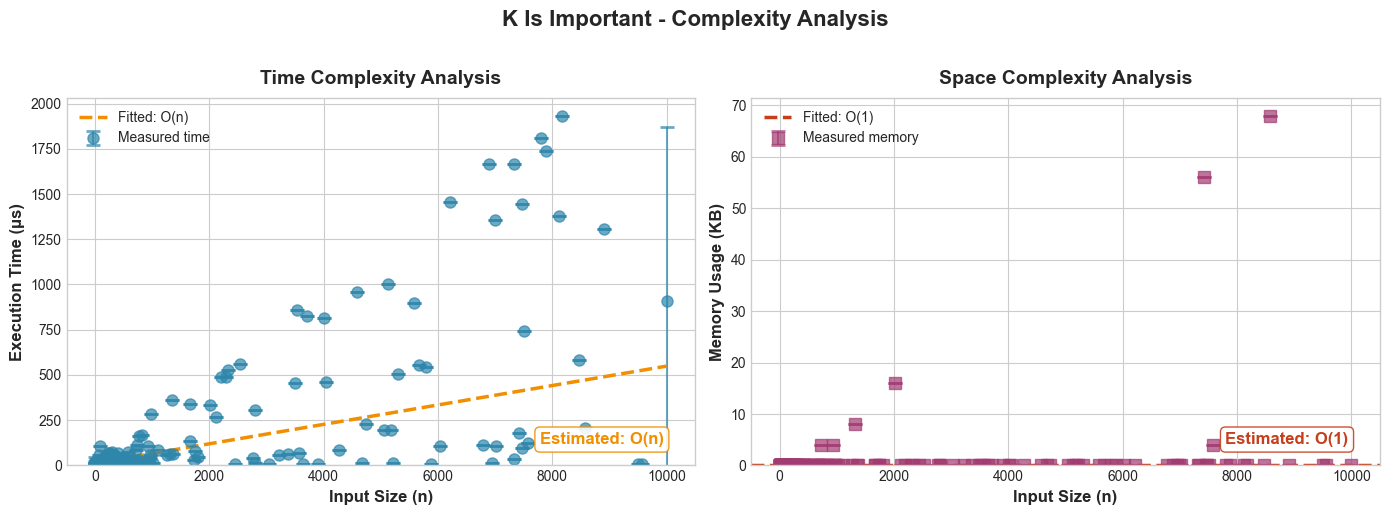


📊 Estimated Time Complexity: O(n)
📊 Estimated Space Complexity: O(1)
✅ The proposed solution meets both accuracy and efficiency requirements


In [7]:
##################### VERIFY PROPOSED SOLUTION ########################

print("\nTesting proposed solution on hidden tests:")
if internal_evaluation(test_file_path, proposed_solution, check_solution, parse_tests, TIME_LIMIT, MEMORY_LIMIT, get_input_size=get_input_size, plot_title='K Is Important', show_estimation=True):
    print("✅ The proposed solution meets both accuracy and efficiency requirements")

<p style="padding: 20px;
          background-color: green;
          font-family: computermodern;
          color: white;
          font-size: 200%;
          text-align: center;
          border-radius: 40px 20px;
          ">Thank you! If you found this useful, please upvote 👍</p>